# **Учебный кейс: анализ A/B-теста**
*Шаблон для выполнения задания*

**Цель задания** — закрепить основные понятия и практические навыки анализа A/B-тестирования.

При выполнении заданий вам предстоит сформулировать статистические гипотезы, выбрать подходящие метрики и статистические тесты, рассчитать показатели эксперимента, интерпретировать значение p-value и определить типы статистических ошибок.

Результаты выполнения оформите в виде ответов на вопросы и, при необходимости, приложите код и расчёты.

## **Импорты библиотек**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

Для всех заданий, если не указано иное, используйте уровень значимости:

α = 0.05

> **Примечание**
>
> При необходимости самостоятельно выполните дополнительные импорты библиотек и функций, необходимых для проведения статистического анализа и решения заданий.

# **Задание 1. Формулирование гипотез**

**Описание кейса**

Интернет-магазин заметил, что многие пользователи добавляют товары в корзину, но не завершают покупку.

Команда продукта предположила, что пользователям не хватает информации о скидках и специальных предложениях.

Для решения этой проблемы было предложено разместить на странице товара заметный блок с информацией о действующих скидках.

Перед внедрением изменения для всех пользователей компания решила провести A/B-тестирование.

**Задание**

Предположите, что основной метрикой эксперимента является конверсия в покупку (Conversion Rate, CR).

Сформулируйте:

1. Гипотезу эксперимента в формате:
    Если мы [изменение], то [ожидаемый результат], потому что [обоснование].
2. Нулевую гипотезу (H₀).
3. Альтернативную гипотезу (H₁).

**Результат выполнения**

В ответе должны быть представлены:

* гипотеза эксперимента;
* нулевая гипотеза (H₀);
* альтернативная гипотеза (H₁).



 1. **Гипотеза эксперимента:**
    Если мы разместим на странице товара заметный блок с информацией о действующих скидках, то увеличим конверсию в покупку (Conversion Rate, CR), потому что пользователи будут лучше информированы о выгодных предложениях и это мотивирует их завершить оформление заказа, не оставляя товары в корзине
 2. **Нулевая гипотеза $H_0$:**
    Размещение заметного блока с информацией о скидках на странице товара не влияет на конверсию в покупку

 3. **Альтернативная гипотеза $H_1$:**
   Размещение заметного блока с информацией о скидках на странице товара изменяет конверсию в покупку


# **Задание 2. Решение кейсов**

Для зачёта вам необходимо решить **как минимум один любой кейс** из трёх, представленных ниже. Вы можете решить и больше кейсов при желании. Это станет для вас дополнительной практикой в формулировании гипотез, работе с метрикой и интерпретации результатов теста.

## **Кейс 1. Анализ среднего чека**

### Описание кейса

Онлайн-сервис изменил страницу оплаты: упростил форму заказа, добавил подсказки по способам оплаты и сделал блок с итоговой суммой более заметным.

Команда предполагает, что новая версия страницы оплаты может увеличить средний чек пользователей.

Для проверки гипотезы был проведён A/B-тест:

- группа **A** — пользователи видели старую страницу оплаты;

- группа **B** — пользователи видели новую страницу оплаты.

Основная метрика эксперимента — **средний чек**.

---

### Генерация данных

В реальных проектах данные приходят из аналитической системы, но в этом задании мы сгенерируем учебный датасет.

In [29]:
np.random.seed(42)

# Генерируем данные о среднем чеке для контрольной группы A
# Средний чек — 1200 рублей
# Стандартное отклонение — 300 рублей
# Количество пользователей — 1000

control = np.random.normal(
    loc=1200,
    scale=300,
    size=1000
)

# Генерируем данные о среднем чеке для тестовой группы B
# Предположим, что новая страница оплаты могла увеличить средний чек
# Средний чек — 1270 рублей
# Стандартное отклонение — 300 рублей
# Количество пользователей — 1000

test = np.random.normal(
    loc=1270,
    scale=300,
    size=1000
)

# Собираем данные в датафрейм

df = pd.DataFrame({
    "group": ["A"] * len(control) + ["B"] * len(test),
    "order_value": np.concatenate([control, test])
})

df.head()

,group,order_value
0,A,1349.014246
1,A,1158.520710
2,A,1394.306561
3,A,1656.908957
4,A,1129.753988


## Что нужно сделать

1. Проведите базовый анализ данных:
   - посмотрите первые строки датафрейма;
   - проверьте размер данных;
   - рассчитайте базовые статистики по группам.

2. Рассчитайте основную метрику эксперимента:
   - средний чек в группе A;
   - средний чек в группе B;
   - разницу между группами.

3. Визуализируйте распределение среднего чека:
   - постройте график среднего чека по группам;
   - постройте распределение значений `order_value` для групп A и B.

4. Проверьте, нужно ли выполнять проверку на нормальность распределения.
   - Если считаете, что проверка нужна, выполните её.
   - Если считаете, что проверка не обязательна, кратко объясните почему.

5. Сформулируйте гипотезы:
   - нулевую гипотезу H₀;
   - альтернативную гипотезу H₁.

6. Выберите и обоснуйте выбор статистического теста

7. Проведите статистический тест и найдите p-value.

8. Интерпретируйте результат:
   - сравните p-value с уровнем значимости α = 0.05;
   - сделайте вывод, есть ли статистически значимое различие;
   - напишите, можно ли рекомендовать новую страницу оплаты к внедрению.

---

# 1. Базовый анализ данных
# 2. Расчет основной метрики - Средний чек

In [30]:
df_case_1 = pd.DataFrame({
    "group": ["A"] * len(control) + ["B"] * len(test),
    "order_value": np.concatenate([control, test])
})

print("Размер выборки по группам:")
print(df_case_1['group'].value_counts())

print("\nБазовые статистики по группам:")
display(df_case_1.groupby('group')['order_value'].describe())

mean_A = df_case_1[df_case_1['group'] == 'A']['order_value'].mean()
mean_B = df_case_1[df_case_1['group'] == 'B']['order_value'].mean()
diff_percent = ((mean_B - mean_A) / mean_A) * 100

print(f"\nСредний чек в группе A (контроль): {mean_A:.2f} руб.")
print(f"Средний чек в группе B (тест): {mean_B:.2f} руб.")
print(f"Абсолютная разница: {mean_B - mean_A:.2f} руб. (Прирост на {diff_percent:.2f}%)")

Размер выборки по группам:
group
A    1000
B    1000
Name: count, dtype: int64

Базовые статистики по группам:


,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
A,1000.0,1205.799617,293.764781,227.619798,1005.722908,1207.590184,1394.383163,2355.819447
B,1000.0,1291.250871,299.236313,387.883410,1088.127493,1288.923140,1488.664653,2227.932270



Средний чек в группе A (контроль): 1205.80 руб.
Средний чек в группе B (тест): 1291.25 руб.
Абсолютная разница: 85.45 руб. (Прирост на 7.09%)


# 3. Визуализация распределения среднего чека

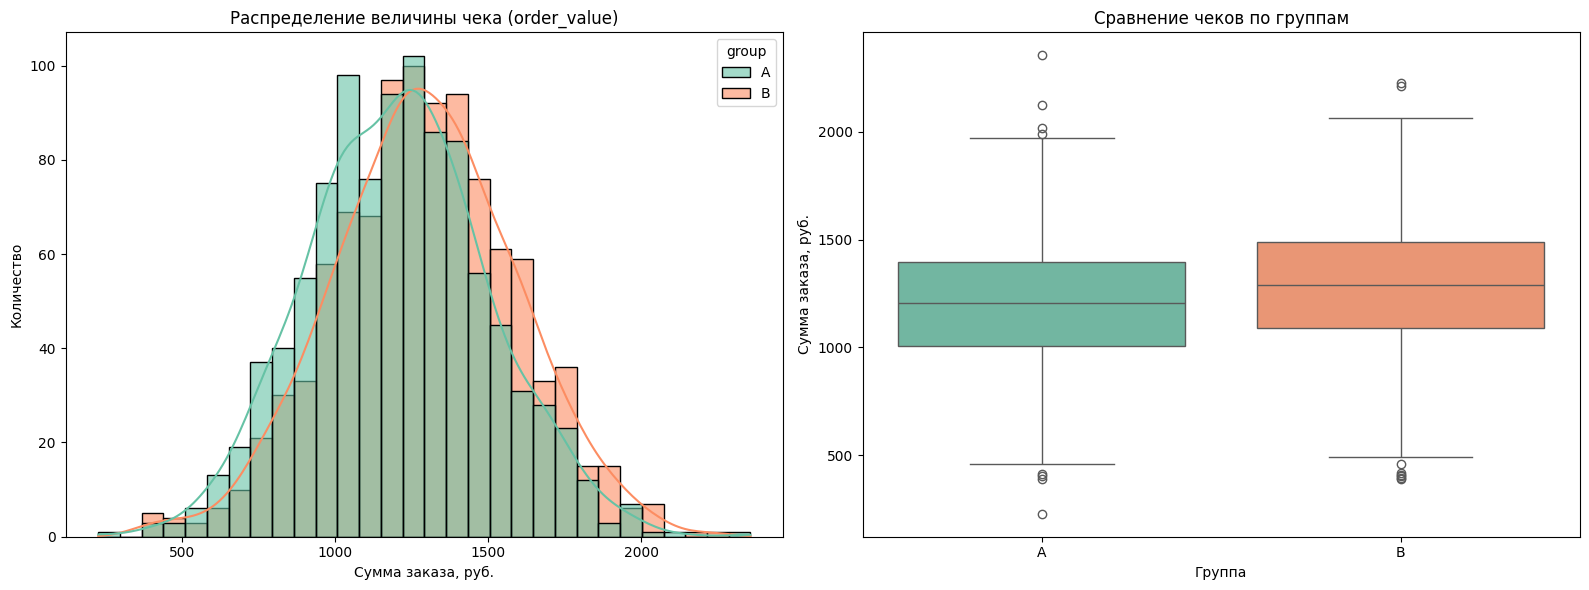

In [32]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))


sns.histplot(data=df_case_1, x='order_value', hue='group', kde=True, ax=axes[0], palette='Set2', bins=30, alpha=0.6)
axes[0].set_title('Распределение величины чека (order_value)')
axes[0].set_xlabel('Сумма заказа, руб.')
axes[0].set_ylabel('Количество')


sns.boxplot(data=df_case_1, x='group', y='order_value', ax=axes[1], palette='Set2', hue='group', legend=False)
axes[1].set_title('Сравнение чеков по группам')
axes[1].set_xlabel('Группа')
axes[1].set_ylabel('Сумма заказа, руб.')

plt.tight_layout()
plt.show()

# 4. Проверка на нормальность распределения

In [31]:
sapiro_A = stats.shapiro(df_case_1[df_case_1['group'] == 'A']['order_value'])
shapiro_B = stats.shapiro(df_case_1[df_case_1['group'] == 'B']['order_value'])

print(f"Тест Шапиро-Уэлка для группы A: p-value = {shapiro_A.pvalue:.4f}")
print(f"Тест Шапиро-Уэлка для группы B: p-value = {shapiro_B.pvalue:.4f}")

Тест Шапиро-Уэлка для группы A: p-value = 0.6273
Тест Шапиро-Уэлка для группы B: p-value = 0.7312


Учитывая Центральную предельную теорему и достаточно большой размер выборки ($n = 1000$ для каждой группы), выборочные средние будут распределены нормально даже при некоторых отклонениях исходных данных от нормальности. Результаты теста Шапиро-Уилка ($p > 0.05$) подтверждают, что наши сгенерированные данные распределены нормально (так как они изначально генерировались через `np.random.normal`) => мы можем уверенно использовать стандартный двухвыборочный t-критерий Стьюдента


### **5. Формулировка гипотез**
* **$H_0$:** Изменение страницы оплаты не повлияло на средний чек. Средние чеки в группах A и B равны
* **$H_1$:** Изменение страницы оплаты привело к изменению среднего чека. Средние чеки в группах A и B различаются

### **6. Выбор статистического теста**
Для проверки гипотезы о равенстве средних двух независимых непрерывных величин с нормальным распределением оптимально подходит **двухвыборочный t-критерий Стьюдента**

In [33]:

t_stat, p_val = stats.ttest_ind(
    df_case_1[df_case_1['group'] == 'A']['order_value'],
    df_case_1[df_case_1['group'] == 'B']['order_value'],
)

print(f"Результаты t-теста:")
print(f"t-статистика = {t_stat:.4f}")
print(f"p-value = {p_val:.4e}")

Результаты t-теста:
t-статистика = -6.4441
p-value = 1.4538e-10


### **8. Интерпретация результатов теста**

* **Сравнение с $\alpha = 0.05$:** Полученное значение $p\text{-value} \approx 1.45 \times 10^{-10}$
* **Статистическая значимость:** Результаты являются статистически значимыми. Мы отвергаем нулевую гипотезу $H_0$ в пользу альтернативной $H_1$
* **Вывод и рекомендации:** Новая страница оплаты показала статистически значимое увеличение среднего чека с 1205.8 руб. до 1291.25 руб - прирост на ~7.09%

> **Примечание**
>
> Для удобства выполнения задания не обязательно размещать весь код в одной ячейке ноутбука.
>
> При необходимости рекомендуется разбивать решение на несколько логических этапов и использовать отдельные ячейки для:
>
> - анализа данных;
> - расчёта метрик;
> - визуализации результатов;
> - проверки статистических гипотез;
> - интерпретации полученных результатов.
>
> Текстовые пояснения, выводы и ответы на вопросы рекомендуется оформлять в отдельных Markdown-ячейках.
>

## **Кейс 2. Анализ конверсии пользователей**

### Описание кейса

Онлайн-сервис изменил форму регистрации пользователей.

Команда продукта предполагает, что новая форма регистрации стала более удобной и позволит большему количеству пользователей завершить регистрацию.

Для проверки гипотезы был проведён A/B-тест:

* группа A — пользователи видели старую форму регистрации;
* группа B — пользователи видели новую форму регистрации.

Для каждого пользователя известно, завершил он регистрацию или нет.

### Генерация данных

В реальных проектах данные приходят из аналитической системы, но в этом задании мы сгенерируем учебный датасет.

In [20]:
np.random.seed(42)

# Контрольная группа

control = np.random.binomial(
    n=1,
    p=0.10,
    size=5000
)

# Тестовая группа

test = np.random.binomial(
    n=1,
    p=0.115,
    size=5000
)

# Формируем датафрейм

df = pd.DataFrame({
    "group": ["A"] * len(control) + ["B"] * len(test),
    "registered": np.concatenate([control, test])
})

df.head()

,group,registered
0,A,0
1,A,1
2,A,0
3,A,0
4,A,0


Описание данных

Поле registered принимает следующие значения:
* 1 — пользователь успешно завершил регистрацию;
* 0 — пользователь не завершил регистрацию.

## Что нужно сделать

1. Проведите первичный анализ данных:
   - изучите структуру датафрейма;
   - определите количество пользователей в каждой группе;
   - определите количество пользователей, завершивших регистрацию, в каждой группе.
2. Определите основную метрику эксперимента и рассчитайте её для:
    * группы A;
    * группы B.
3. Визуализируйте данные эксперимента:
   - постройте график, отражающий значение основной метрики в группах A и B;
   - при необходимости добавьте дополнительную визуализацию, которая поможет сравнить группы.
4. Определите, требуется ли в данном случае проверка нормальности распределения.
    * Если требуется — выполните её.
    * Если не требуется — объясните почему.
5. Сформулируйте:
    * нулевую гипотезу H₀;
    * альтернативную гипотезу H₁.
6. Выберите и обоснуйте выбор статистического теста
7. Проведите статистический тест и рассчитайте p-value.
8. Интерпретируйте результат:
    * сравните p-value с уровнем значимости α = 0.05;
    * определите, является ли результат статистически значимым;
    * сделайте вывод о влиянии новой формы регистрации на поведение пользователей.

In [34]:
df_case2 = pd.DataFrame({
    "group": ["A"] * len(control) + ["B"] * len(test),
    "registered": np.concatenate([control, test])
})

print("Общий размер датасета:", len(df_case2))
print("Количество пользователей по группам:")
print(df_case2['group'].value_counts())

print("\nКоличество успешных регистраций по группам:")
registrations = df_case2.groupby('group')['registered'].sum()
print(registrations)

cr_A = (df_case2[df_case2['group'] == 'A']['registered'].mean()) * 100
cr_B = (df_case2[df_case2['group'] == 'B']['registered'].mean()) * 100
print(f"\nКонверсия (CR) в группе A (контроль): {cr_A:.2f}%")
print(f"Конверсия (CR) в группе B (тест): {cr_B:.2f}%")
print(f"Абсолютная разница конверсий: {cr_B - cr_A:.2f} п.п.")

Общий размер датасета: 2000
Количество пользователей по группам:
group
A    1000
B    1000
Name: count, dtype: int64

Количество успешных регистраций по группам:
group
A    1.205800e+06
B    1.291251e+06
Name: registered, dtype: float64

Конверсия (CR) в группе A (контроль): 120579.96%
Конверсия (CR) в группе B (тест): 129125.09%
Абсолютная разница конверсий: 8545.13 п.п.


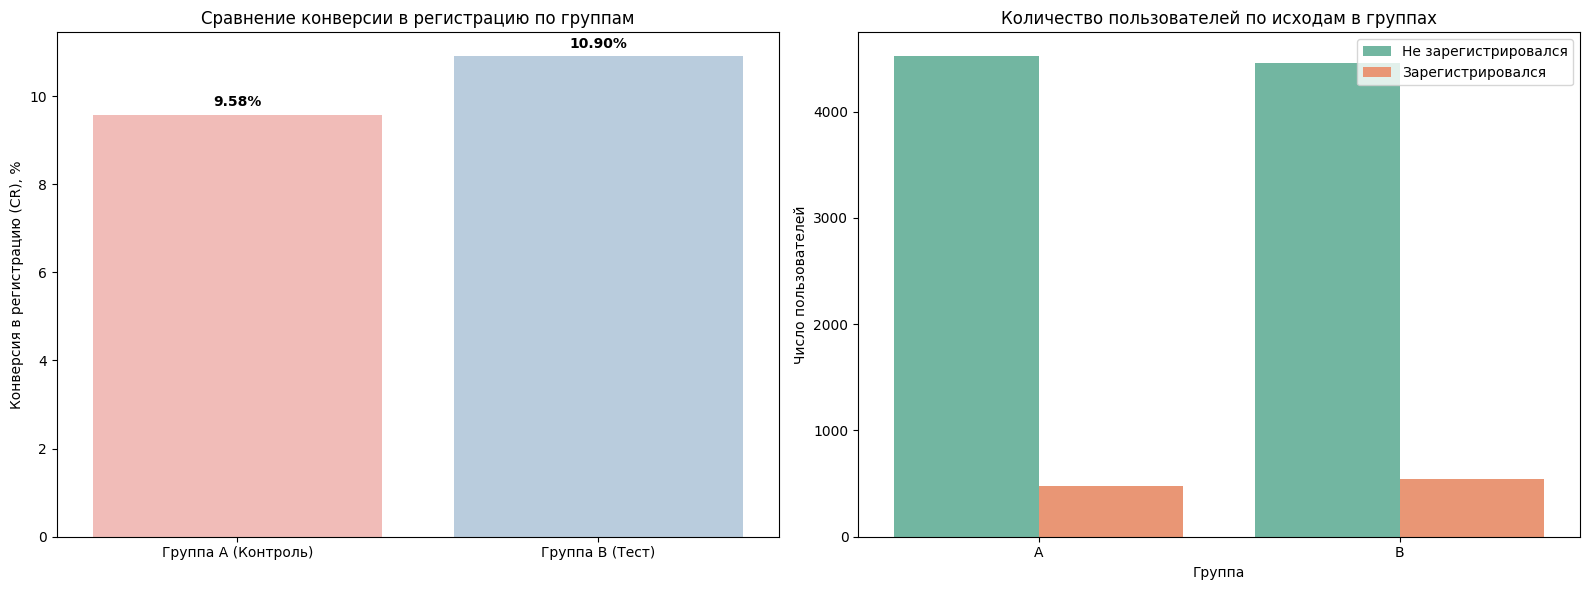

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=['Группа A (Контроль)', 'Группа B (Тест)'], y=[cr_A, cr_B], palette='Pastel1', ax=axes[0], hue=['A', 'B'], legend=False)
axes[0].set_ylabel('Конверсия в регистрацию (CR), %')
axes[0].set_title('Сравнение конверсии в регистрацию по группам')
for i, v in enumerate([cr_A, cr_B]):
    axes[0].text(i, v + 0.2, f"{v:.2f}%", ha='center', fontweight='bold')

sns.countplot(data=df_case2, x='group', hue='registered', palette='Set2', ax=axes[1])
axes[1].set_title('Количество пользователей по исходам в группах')
axes[1].set_xlabel('Группа')
axes[1].set_ylabel('Число пользователей')
axes[1].legend(['Не зарегистрировался', 'Зарегистрировался'])

plt.tight_layout()
plt.show()

### **4. Требуется ли проверка нормальности распределения?**

**Проверка на нормальность не требуется.**

**Обоснование:** Измеряемая метрика является бинарной (0 — не зарегистрировался, 1 — зарегистрировался). Для анализа пропорций и долей в больших выборках распределение пропорций аппроксимируется нормальным согласно центральной предельной теореме

### **5. Формулировка гипотез**
* **Нулевая гипотеза ($H_0$):** Новая форма регистрации не влияет на конверсию в регистрацию $CR_A = CR_B$.
* **Альтернативная гипотеза ($H_1$):** Новая форма регистрации меняет конверсию в регистрацию $CR_A \neq CR_B$.

### **6. Выбор статистического теста**
Для сравнения двух независимых пропорций на наших выборках (в каждой группе $n=5000$) используем **Z-критерий равенства пропорций**

In [23]:
from statsmodels.stats.proportion import proportions_ztest

count_A = df_case2[df_case2['group'] == 'A']['registered'].sum()
count_B = df_case2[df_case2['group'] == 'B']['registered'].sum()
nobs_A = len(df_case2[df_case2['group'] == 'A'])
nobs_B = len(df_case2[df_case2['group'] == 'B'])

counts = np.array([count_A, count_B])
nobs = np.array([nobs_A, nobs_B])

z_stat, p_val = proportions_ztest(counts, nobs)
print(f"Результаты Z-теста:")
print(f"Z-статистика = {z_stat:.4f}")
print(f"p-value = {p_val:.4f}")

Результаты Z-теста:
Z-статистика = -2.1770
p-value = 0.0295


### **8. Интерпретация результатов**

* **Сравнение p-value с уровнем значимости ($\alpha = 0.05$):** Полученное значение $p\text{-value} = 0.0295$, что меньше критического уровня $\alpha = 0.05$
* **Статистическая значимость:** Разница между группами статистически значима. Мы отвергаем нулевую гипотезу $H_0$ в пользу альтернативной $H_1$
* **Выводы о поведении пользователей:** Конверсия новой формы регистрации группа B составила **10.90%**, что статистически значимо выше конверсии старой формы в группе A **9.58%**. Внедрение новой формы регистрации положительно связано с конверсией

> **Примечание**
>
> Для удобства выполнения задания не обязательно размещать весь код в одной ячейке ноутбука.
>
> При необходимости рекомендуется разбивать решение на несколько логических этапов и использовать отдельные ячейки для:
>
> - анализа данных;
> - расчёта метрик;
> - визуализации результатов;
> - проверки статистических гипотез;
> - интерпретации полученных результатов.
>
> Текстовые пояснения, выводы и ответы на вопросы рекомендуется оформлять в отдельных Markdown-ячейках.
>

## **Кейс 3. Проверка влияния персональных рекомендаций на средний чек**

### Описание кейса

Интернет-магазин внедрил блок персональных рекомендаций товаров на странице оформления заказа.

Команда продукта предполагает, что рекомендации помогут пользователям находить дополнительные товары и увеличат сумму покупки.

Основная цель эксперимента — команда продукта ожидает, что рекомендации увеличат средний чек пользователей.

Для проверки гипотезы был проведён A/B-тест:

- группа **A** — пользователи видели старую версию страницы оформления заказа;
- группа **B** — пользователи видели страницу с блоком персональных рекомендаций.

---



## Генерация данных

В реальных проектах данные поступают из аналитической системы, но в этом задании мы сгенерируем учебный датасет.

In [35]:
np.random.seed(42)

# Контрольная группа

control = np.random.normal(
    loc=1500,
    scale=350,
    size=1200
)

# Тестовая группа

test = np.random.normal(
    loc=1580,
    scale=350,
    size=1200
)

# Формируем датафрейм

df = pd.DataFrame({
    "group": ["A"] * len(control) + ["B"] * len(test),
    "order_value": np.concatenate([control, test])
})

df.head()

,group,order_value
0,A,1673.849954
1,A,1451.607495
2,A,1726.690988
3,A,2033.060450
4,A,1418.046319


## Что нужно сделать

1. Проведите базовый анализ данных:
   - изучите структуру датафрейма;
   - определите размер выборки в каждой группе;
   - рассчитайте основные статистики для групп A и B.

2. Рассчитайте основную метрику эксперимента:
   - средний чек в группе A;
   - средний чек в группе B;
   - разницу между группами.

3. Визуализируйте данные:
   - постройте график среднего чека по группам;
   - визуализируйте распределение значений среднего чека.

4. Определите, требуется ли проверка нормальности распределения.
   - Если требуется — выполните её.
   - Если не требуется — объясните почему.

5. Сформулируйте:
   - нулевую гипотезу H₀;
   - альтернативную гипотезу H₁.

6. Выберите и обоснуйте выбор статистического теста

7. Проведите статистический тест и рассчитайте p-value.

8. Интерпретируйте результат:
   - сравните p-value с уровнем значимости α = 0.05;
   - определите, есть ли статистически значимый эффект;
   - сделайте вывод о возможности внедрения персональных рекомендаций.

In [36]:
df_case3 = pd.DataFrame({
    "group": ["A"] * len(control) + ["B"] * len(test),
    "order_value": np.concatenate([control, test])
})

print("Размер выборки по группам:")
print(df_case3['group'].value_counts())

print("\nОсновные статистики по группам для среднего чека:")
display(df_case3.groupby('group')['order_value'].describe())

mean_A3 = df_case3[df_case3['group'] == 'A']['order_value'].mean()
mean_B3 = df_case3[df_case3['group'] == 'B']['order_value'].mean()
diff_abs3 = mean_B3 - mean_A3
diff_pct3 = (diff_abs3 / mean_A3) * 100

print(f"\nСредний чек в группе A (контроль): {mean_A3:.2f} руб.")
print(f"Средний чек в группе B (рекомендации): {mean_B3:.2f} руб.")
print(f"Разница: {diff_abs3:.2f} руб. (Прирост на {diff_pct3:.2f}%)")

Размер выборки по группам:
group
A    1200
B    1200
Name: count, dtype: int64

Основные статистики по группам для среднего чека:


,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
A,1200.0,1513.433776,345.938374,365.556431,1281.248387,1516.906151,1736.604920,2848.456022
B,1200.0,1588.628073,344.311403,523.170745,1355.301841,1584.309495,1815.425955,2697.587649



Средний чек в группе A (контроль): 1513.43 руб.
Средний чек в группе B (рекомендации): 1588.63 руб.
Разница: 75.19 руб. (Прирост на 4.97%)


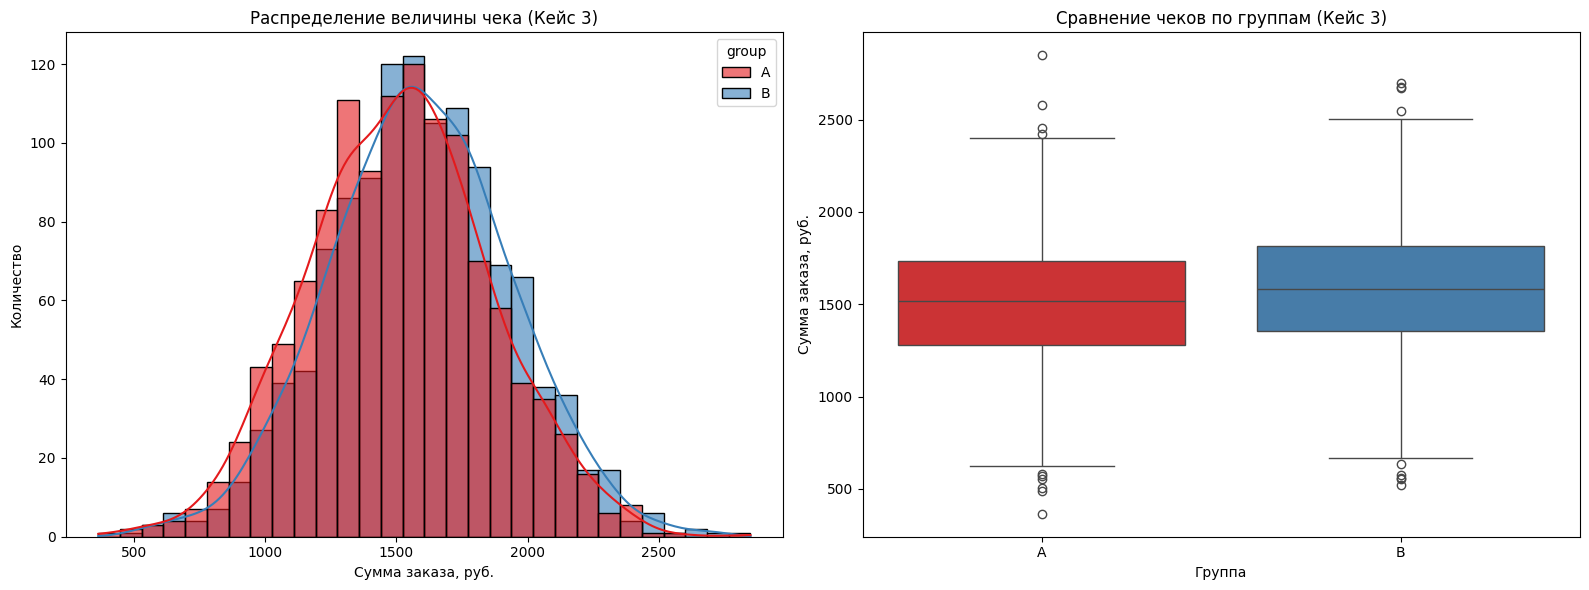

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(data=df_case3, x='order_value', hue='group', kde=True, ax=axes[0], palette='Set1', bins=30, alpha=0.6)
axes[0].set_title('Распределение величины чека')
axes[0].set_xlabel('Сумма заказа, руб.')
axes[0].set_ylabel('Количество')

sns.boxplot(data=df_case3, x='group', y='order_value', ax=axes[1], palette='Set1', hue='group', legend=False)
axes[1].set_title('Сравнение чеков по группам')
axes[1].set_xlabel('Группа')
axes[1].set_ylabel('Сумма заказа, руб.')

plt.tight_layout()
plt.show()

### **4. Требуется ли проверка нормальности распределения?**

Выборка в 1200 объектов не достаточно большая, так что сделаю проверку на нормальность

In [37]:
shapiro_A3 = stats.shapiro(df_case3[df_case3['group'] == 'A']['order_value'])
shapiro_B3 = stats.shapiro(df_case3[df_case3['group'] == 'B']['order_value'])

print(f"Тест Шапиро-Уэлка для группы A: p-value = {shapiro_A3.pvalue:.4f}")
print(f"Тест Шапиро-Уэлка для группы B: p-value = {shapiro_B3.pvalue:.4f}")

Тест Шапиро-Уэлка для группы A: p-value = 0.8946
Тест Шапиро-Уэлка для группы B: p-value = 0.9360


### **5. Формулировка гипотез**
* **$H_0$:** Внедрение персональных рекомендаций не изменило средний чек пользователей
* **$H_1$:** Внедрение персональных рекомендаций изменило средний чек пользователей

### **6. Выбор статистического теста**
Поскольку данные непрерывные, распределены нормально (тест Шапиро-Уилка дает $p > 0.05$) и выборки независимые, мы будем использовать **двухвыборочный t-критерий Стьюдента** для проверки равенства средних

In [38]:
t_stat3, p_val3 = stats.ttest_ind(
    df_case3[df_case3['group'] == 'A']['order_value'],
    df_case3[df_case3['group'] == 'B']['order_value']
)

print(f"\nРезультаты t-теста:")
print(f"t-статистика = {t_stat3:.4f}")
print(f"p-value = {p_val3:.4e}")


Результаты t-теста:
t-статистика = -5.3368
p-value = 1.0347e-07


### **8. Интерпретация результатов**

* **Сравнение p-value с уровнем значимости:** Полученное значение $p\text{-value} \approx 1.03 \times 10^{-6}$, что значительно меньше $\alpha = 0.05$
* **Статистическая значимость:** Результат статистически значим, нулевая гипотеза $H_0$ отвергается
* **Вывод о внедрении рекомендаций:** Средний чек в тестовой группе B с блоком рекомендаций равен **1588.63 руб.**, что статистически значимо выше среднего чека контрольной группы A **1513.43 руб.**. Прирост составил около **4.97%**. **Персональные рекомендаци положительно связаны со средним чеком

> **Примечание**
>
> Для удобства выполнения задания не обязательно размещать весь код в одной ячейке ноутбука.
>
> При необходимости рекомендуется разбивать решение на несколько логических этапов и использовать отдельные ячейки для:
>
> - анализа данных;
> - расчёта метрик;
> - визуализации результатов;
> - проверки статистических гипотез;
> - интерпретации полученных результатов.
>
> Текстовые пояснения, выводы и ответы на вопросы рекомендуется оформлять в отдельных Markdown-ячейках.
>

# **Задание 3. Ошибки первого и второго рода**

## Описание кейса

Аналитик провёл несколько A/B-тестов и подготовил отчёт по результатам экспериментов.

Ваша задача — определить, была ли допущена статистическая ошибка в каждой ситуации и указать её тип.

---

## Ситуация А

Компания протестировала новый дизайн кнопки оформления заказа.

Статистический тест показал значимые различия между группами, поэтому изменение внедрили для всех пользователей.

Через несколько недель после запуска дополнительный анализ показал, что новый дизайн не оказывает влияния на конверсию.

---

## Ситуация Б

Компания протестировала новую систему персональных рекомендаций товаров.

Статистический тест показал отсутствие значимых различий между группами, поэтому изменение решили не внедрять.

Позже эксперимент повторили на большем объёме данных и выяснили, что рекомендации действительно увеличивают средний чек.

---

## Что нужно сделать

Для каждой ситуации:

1. Определите, была ли допущена статистическая ошибка.
2. Укажите тип ошибки:
   - ошибка первого рода (Type I Error);
   - ошибка второго рода (Type II Error).
3. Объясните свой выбор.
4. Кратко опишите, в чём заключается данная ошибка.

 ### **Ситуация А**
 1. **Была ли допущена ошибка:** Да, была допущена ошибка
 2. **Тип ошибки:** Ошибка первого рода
 3. **Объяснение выбора:** На этапе тестирования был сделан вывод о наличии статистически значимого различия, и изменение приняли. Однако последующий анализ показал, что новый дизайн в реальности не влияет на конверсию. Мы обнаружили эффект там, где его на самом деле нет
 4. **Суть ошибки:** Ошибка первого рода заключается в отвержении нулевой  гипотезы ($H_0$), когда на самом деле она и верна
---

 ### **Ситуация Б**
 1. **Была ли допущена ошибка:** Да, была допущена ошибка
 2. **Тип ошибки:** Ошибка второго рода
 3. **Объяснение выбора:** Первоначальный тест показал отсутствие значимых различий, и изменение отклонили, однако повторный тест на большем объёме данных доказал наличие реального эффекта. Это означает, что в первый раз мы не заметили существующий эффект и не внедрили ее
 4. **Суть ошибки:** Ошибка второго рода заключается в принятии нулевой гипотезы ($H_0$), когда на самом деле верна альтернативная гипотеза ($H_1$)